In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư mục gốc dự án
PROJECT_DIR = Path.cwd().resolve()

# Notebook thường chạy từ thư mục notebooks
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "dataset"
MANIFEST_PATH = PROJECT_DIR / "metadata" / "dataset_split_manifest.csv"

# Đọc metadata sau khi chia dữ liệu
df = pd.read_csv(MANIFEST_PATH)

print("===== DATASET OVERVIEW =====")
print("Total images:", len(df))
print("Classes:", sorted(df["label"].unique()))
print("Splits:", sorted(df["split"].unique()))

display(df.head(10))


===== DATASET OVERVIEW =====
Total images: 450
Classes: ['moving', 'sitting', 'standing']
Splits: ['test', 'train', 'val']


,file_name,label,split,source_path,output_path
0,000000213171.jpg,standing,train,dataset_final\standing\000000213171.jpg,dataset\train\standing\000000213171.jpg
1,000000488251.jpg,standing,train,dataset_final\standing\000000488251.jpg,dataset\train\standing\000000488251.jpg
2,000000367228.jpg,standing,train,dataset_final\standing\000000367228.jpg,dataset\train\standing\000000367228.jpg
3,000000489611.jpg,standing,train,dataset_final\standing\000000489611.jpg,dataset\train\standing\000000489611.jpg
4,000000250127.jpg,standing,train,dataset_final\standing\000000250127.jpg,dataset\train\standing\000000250127.jpg
5,000000212573.jpg,standing,train,dataset_final\standing\000000212573.jpg,dataset\train\standing\000000212573.jpg
6,000000473869.jpg,standing,train,dataset_final\standing\000000473869.jpg,dataset\train\standing\000000473869.jpg
7,000000125257.jpg,standing,train,dataset_final\standing\000000125257.jpg,dataset\train\standing\000000125257.jpg
8,000000130579.jpg,standing,train,dataset_final\standing\000000130579.jpg,dataset\train\standing\000000130579.jpg
9,000000124442.jpg,standing,train,dataset_final\standing\000000124442.jpg,dataset\train\standing\000000124442.jpg


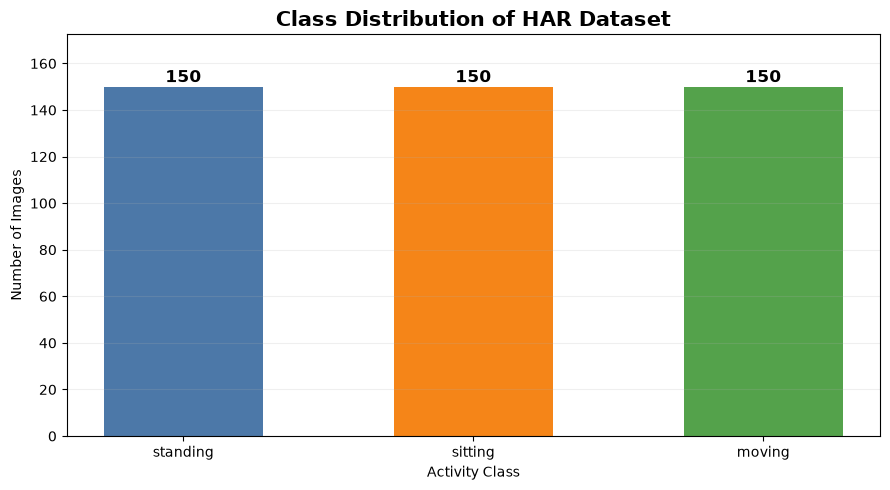

Saved: C:\Users\Dell\OneDrive - Hanoi University of Science and Technology\Desktop\HAR_CNN_PROJECT\metadata\eda_figures\class_distribution.png

===== CLASS DISTRIBUTION =====
label
standing    150
sitting     150
moving      150
Name: count, dtype: int64


In [3]:

# EDA 2: Class Distribution

class_order = ["standing", "sitting", "moving"]

class_counts = (
    df["label"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values,
    color=["#4C78A8", "#F58518", "#54A24B"],
    width=0.55
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        str(int(height)),
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "Class Distribution of HAR Dataset",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Activity Class")
plt.ylabel("Number of Images")
plt.ylim(0, max(class_counts) * 1.15)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Tạo thư mục lưu biểu đồ
output_dir = PROJECT_DIR / "metadata" / "eda_figures"
output_dir.mkdir(parents=True, exist_ok=True)

# Lưu biểu đồ với độ phân giải cao
plt.savefig(
    output_dir / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_dir / "class_distribution.png")

print("\n===== CLASS DISTRIBUTION =====")
print(class_counts)


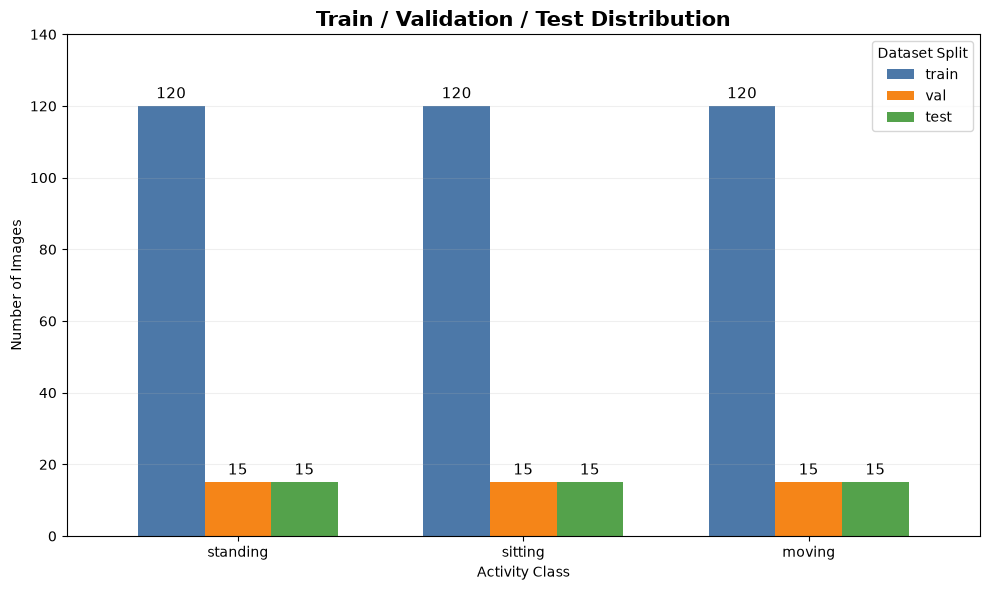


===== SPLIT DISTRIBUTION =====
split     train  val  test
label                     
standing    120   15    15
sitting     120   15    15
moving      120   15    15

Total per split:
split
train    360
val       45
test      45
dtype: int64

STATUS: SPLIT DISTRIBUTION VERIFIED


In [4]:

# EDA 3: Train / Validation / Test Distribution

class_order = ["standing", "sitting", "moving"]
split_order = ["train", "val", "test"]

# Đếm số lượng ảnh theo class và tập dữ liệu
split_counts = pd.crosstab(
    df["label"],
    df["split"]
).reindex(
    index=class_order,
    columns=split_order,
    fill_value=0
)

# Vẽ biểu đồ
ax = split_counts.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#4C78A8", "#F58518", "#54A24B"],
    width=0.7
)

# Hiển thị số lượng trên mỗi cột
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=11)

plt.title(
    "Train / Validation / Test Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Activity Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.ylim(0, 140)
plt.legend(title="Dataset Split")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Lưu biểu đồ
output_dir = PROJECT_DIR / "metadata" / "eda_figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Hiển thị bảng thống kê
print("\n===== SPLIT DISTRIBUTION =====")
print(split_counts)
print("\nTotal per split:")
print(split_counts.sum(axis=0))

# Kiểm tra tỷ lệ chia
assert split_counts["train"].eq(120).all()
assert split_counts["val"].eq(15).all()
assert split_counts["test"].eq(15).all()

print("\nSTATUS: SPLIT DISTRIBUTION VERIFIED")


In [5]:

# EDA 4.1: Load Image Dimension Statistics

stats_path = PROJECT_DIR / "metadata" / "image_statistics.csv"

image_stats = pd.read_csv(stats_path)

print("===== IMAGE STATISTICS =====")
print("Total records:", len(image_stats))
print("\nColumns:")
print(image_stats.columns.tolist())

display(image_stats.head(10))


===== IMAGE STATISTICS =====
Total records: 450

Columns:
['file_name', 'label', 'width', 'height', 'aspect_ratio', 'orientation']


,file_name,label,width,height,aspect_ratio,orientation
0,000000000785.jpg,standing,640,425,1.5059,landscape
1,000000002532.jpg,standing,480,640,0.7500,portrait
2,000000004395.jpg,standing,425,640,0.6641,portrait
3,000000008690.jpg,standing,640,480,1.3333,landscape
4,000000009448.jpg,standing,551,640,0.8609,portrait
5,000000009483.jpg,standing,640,480,1.3333,landscape
6,000000009772.jpg,standing,550,640,0.8594,portrait
7,000000012748.jpg,standing,480,640,0.7500,portrait
8,000000016598.jpg,standing,478,640,0.7469,portrait
9,000000017899.jpg,standing,480,640,0.7500,portrait


In [6]:

# EDA 4.2: Recalculate Image Statistics

from PIL import Image, ImageOps

records = []

for _, row in df.iterrows():
    image_path = PROJECT_DIR / row["output_path"]

    with Image.open(image_path) as img:
        img = ImageOps.exif_transpose(img)
        width, height = img.size

    ratio = width / height

    if ratio > 1.05:
        orientation = "landscape"
    elif ratio < 0.95:
        orientation = "portrait"
    else:
        orientation = "square"

    records.append({
        "file_name": row["file_name"],
        "label": row["label"],
        "split": row["split"],
        "width": width,
        "height": height,
        "aspect_ratio": ratio,
        "orientation": orientation
    })

eda_stats = pd.DataFrame(records)

assert len(eda_stats) == 450
assert eda_stats["file_name"].nunique() == 450

print("===== UPDATED IMAGE STATISTICS =====")
print("Total images:", len(eda_stats))
print("\nOrientation distribution:")
print(eda_stats["orientation"].value_counts())

display(eda_stats.head())

# Lưu thống kê EDA mới, không ghi đè file cũ
eda_stats.to_csv(
    PROJECT_DIR / "metadata" / "eda_image_statistics.csv",
    index=False
)

print("\nSTATUS: SUCCESS")


===== UPDATED IMAGE STATISTICS =====
Total images: 450

Orientation distribution:
orientation
landscape    245
portrait     184
square        21
Name: count, dtype: int64


,file_name,label,split,width,height,aspect_ratio,orientation
0,000000213171.jpg,standing,train,375,500,0.750000,portrait
1,000000488251.jpg,standing,train,640,360,1.777778,landscape
2,000000367228.jpg,standing,train,333,500,0.666000,portrait
3,000000489611.jpg,standing,train,640,622,1.028939,square
4,000000250127.jpg,standing,train,640,640,1.000000,square



STATUS: SUCCESS


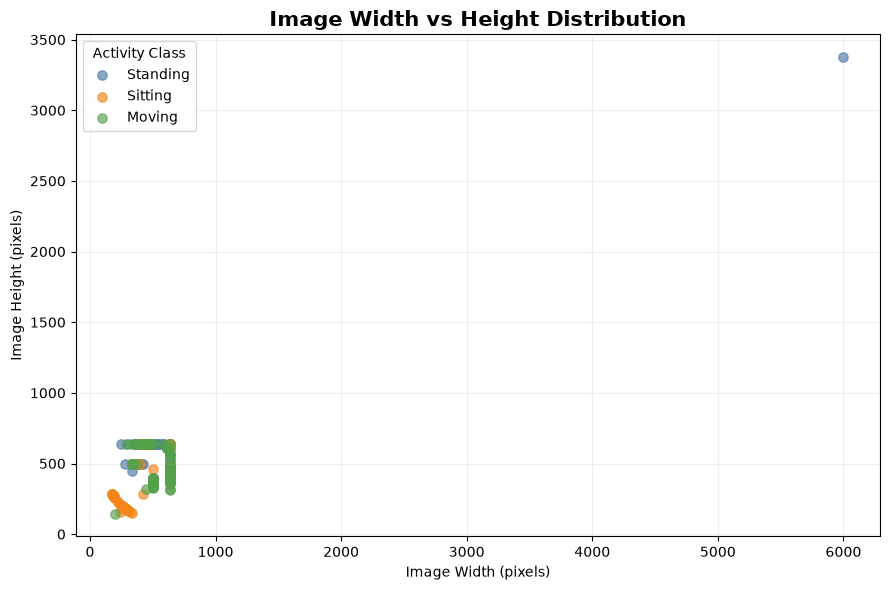

Saved: C:\Users\Dell\OneDrive - Hanoi University of Science and Technology\Desktop\HAR_CNN_PROJECT\metadata\eda_figures\image_dimensions.png


In [7]:

# EDA 4.3: Image Width vs Height

plt.figure(figsize=(9, 6))

colors = {
    "standing": "#4C78A8",
    "sitting": "#F58518",
    "moving": "#54A24B"
}

for label in ["standing", "sitting", "moving"]:
    subset = eda_stats[eda_stats["label"] == label]

    plt.scatter(
        subset["width"],
        subset["height"],
        label=label.capitalize(),
        color=colors[label],
        alpha=0.65,
        s=45
    )

plt.title(
    "Image Width vs Height Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")
plt.legend(title="Activity Class")
plt.grid(alpha=0.2)

plt.tight_layout()

# Lưu biểu đồ
output_dir = PROJECT_DIR / "metadata" / "eda_figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "image_dimensions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_dir / "image_dimensions.png")


In [8]:

# EDA 4.3.1: Identify Image Dimension Outliers

outliers = eda_stats[
    (eda_stats["width"] > 1000) |
    (eda_stats["height"] > 1000)
]

print("===== IMAGE DIMENSION OUTLIERS =====")
print("Number of outliers:", len(outliers))

display(
    outliers[
        ["file_name", "label", "split",
         "width", "height", "aspect_ratio"]
    ]
)


===== IMAGE DIMENSION OUTLIERS =====
Number of outliers: 1


,file_name,label,split,width,height,aspect_ratio
65,man_standing_on_street_unsplash.jpg,standing,train,6000,3376,1.777251


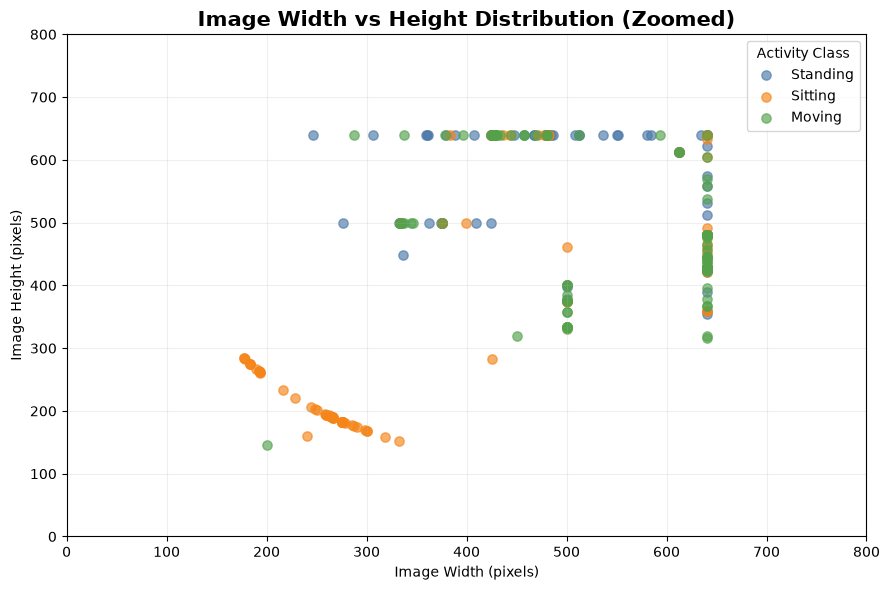

In [9]:

# EDA 4.3.2: Zoomed Image Dimensions

plt.figure(figsize=(9, 6))

colors = {
    "standing": "#4C78A8",
    "sitting": "#F58518",
    "moving": "#54A24B"
}

for label in ["standing", "sitting", "moving"]:
    subset = eda_stats[eda_stats["label"] == label]

    plt.scatter(
        subset["width"],
        subset["height"],
        label=label.capitalize(),
        color=colors[label],
        alpha=0.65,
        s=45
    )

plt.xlim(0, 800)
plt.ylim(0, 800)

plt.title(
    "Image Width vs Height Distribution (Zoomed)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")
plt.legend(title="Activity Class")
plt.grid(alpha=0.2)

plt.tight_layout()

output_dir = PROJECT_DIR / "metadata" / "eda_figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "image_dimensions_zoomed.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


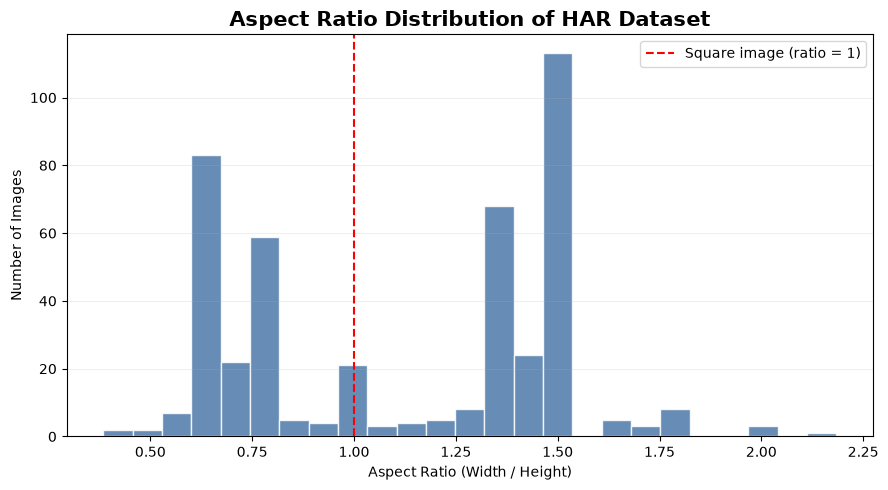


===== ASPECT RATIO STATISTICS =====
count    450.000000
mean       1.120421
std        0.380272
min        0.384375
25%        0.736113
50%        1.313107
75%        1.498829
max        2.184211
Name: aspect_ratio, dtype: float64

Saved: C:\Users\Dell\OneDrive - Hanoi University of Science and Technology\Desktop\HAR_CNN_PROJECT\metadata\eda_figures\aspect_ratio_distribution.png


In [10]:

# EDA 4.4: Aspect Ratio Distribution

plt.figure(figsize=(9, 5))

plt.hist(
    eda_stats["aspect_ratio"],
    bins=25,
    color="#4C78A8",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    x=1.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Square image (ratio = 1)"
)

plt.title(
    "Aspect Ratio Distribution of HAR Dataset",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Images")
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Lưu biểu đồ
output_dir = PROJECT_DIR / "metadata" / "eda_figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "aspect_ratio_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n===== ASPECT RATIO STATISTICS =====")
print(eda_stats["aspect_ratio"].describe())
print("\nSaved:", output_dir / "aspect_ratio_distribution.png")


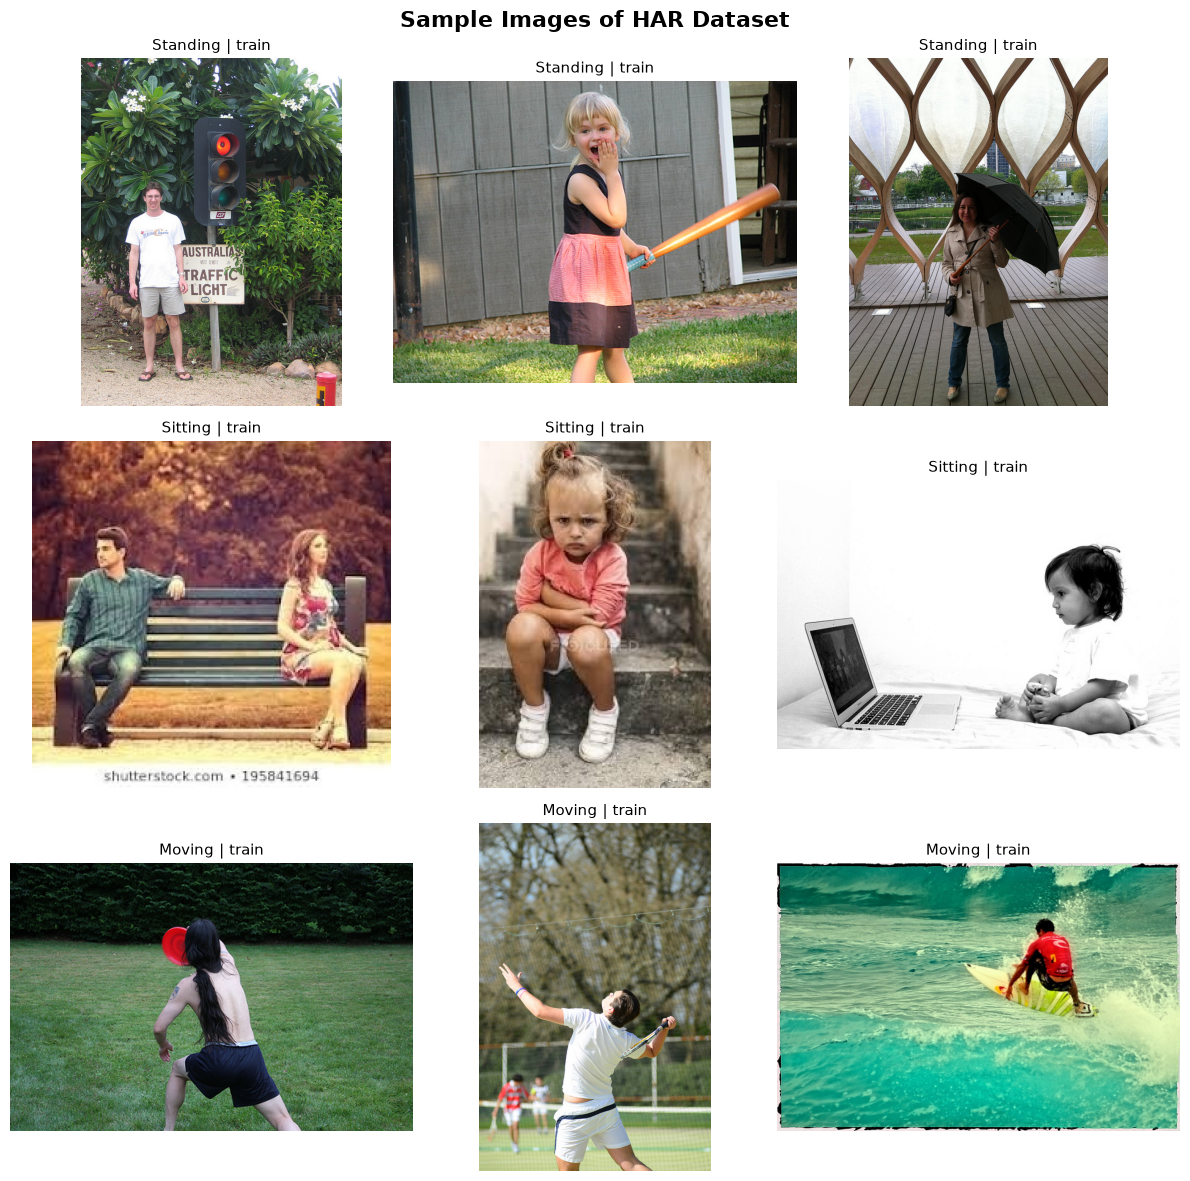

Saved: C:\Users\Dell\OneDrive - Hanoi University of Science and Technology\Desktop\HAR_CNN_PROJECT\metadata\eda_figures\sample_images.png
STATUS: SUCCESS


In [11]:

# EDA 5: Sample Images Visualization

from PIL import Image, ImageOps

classes = ["standing", "sitting", "moving"]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row_idx, label in enumerate(classes):

    subset = df[df["label"] == label]

    # Chọn 3 ảnh ngẫu nhiên, có thể tái lập
    samples = subset.sample(n=3, random_state=42)

    for col_idx, (_, record) in enumerate(samples.iterrows()):

        image_path = PROJECT_DIR / record["output_path"]

        with Image.open(image_path) as img:
            image = ImageOps.exif_transpose(img).convert("RGB")

        ax = axes[row_idx, col_idx]
        ax.imshow(image)
        ax.set_title(
            f"{label.capitalize()} | {record['split']}",
            fontsize=11
        )
        ax.axis("off")

plt.suptitle(
    "Sample Images of HAR Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

output_dir = PROJECT_DIR / "metadata" / "eda_figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_dir / "sample_images.png")
print("STATUS: SUCCESS")


In [12]:

# EDA 6: Final Dataset Summary

summary = pd.DataFrame({
    "Metric": [
        "Total Images",
        "Number of Classes",
        "Training Images",
        "Validation Images",
        "Testing Images",
        "Mean Image Width",
        "Mean Image Height",
        "Mean Aspect Ratio",
        "Landscape Images",
        "Portrait Images",
        "Near-square Images"
    ],
    "Value": [
        len(df),
        df["label"].nunique(),
        (df["split"] == "train").sum(),
        (df["split"] == "val").sum(),
        (df["split"] == "test").sum(),
        round(eda_stats["width"].mean(), 2),
        round(eda_stats["height"].mean(), 2),
        round(eda_stats["aspect_ratio"].mean(), 4),
        (eda_stats["orientation"] == "landscape").sum(),
        (eda_stats["orientation"] == "portrait").sum(),
        (eda_stats["orientation"] == "square").sum()
    ]
})

display(summary)

# Save EDA summary
output_path = PROJECT_DIR / "metadata" / "eda_summary.csv"
summary.to_csv(output_path, index=False)

print("Saved:", output_path)
print("EDA SUMMARY COMPLETED")


,Metric,Value
0,Total Images,450.0000
1,Number of Classes,3.0000
2,Training Images,360.0000
3,Validation Images,45.0000
4,Testing Images,45.0000
5,Mean Image Width,514.0800
6,Mean Image Height,489.5400
7,Mean Aspect Ratio,1.1204
8,Landscape Images,245.0000
9,Portrait Images,184.0000


Saved: C:\Users\Dell\OneDrive - Hanoi University of Science and Technology\Desktop\HAR_CNN_PROJECT\metadata\eda_summary.csv
EDA SUMMARY COMPLETED
